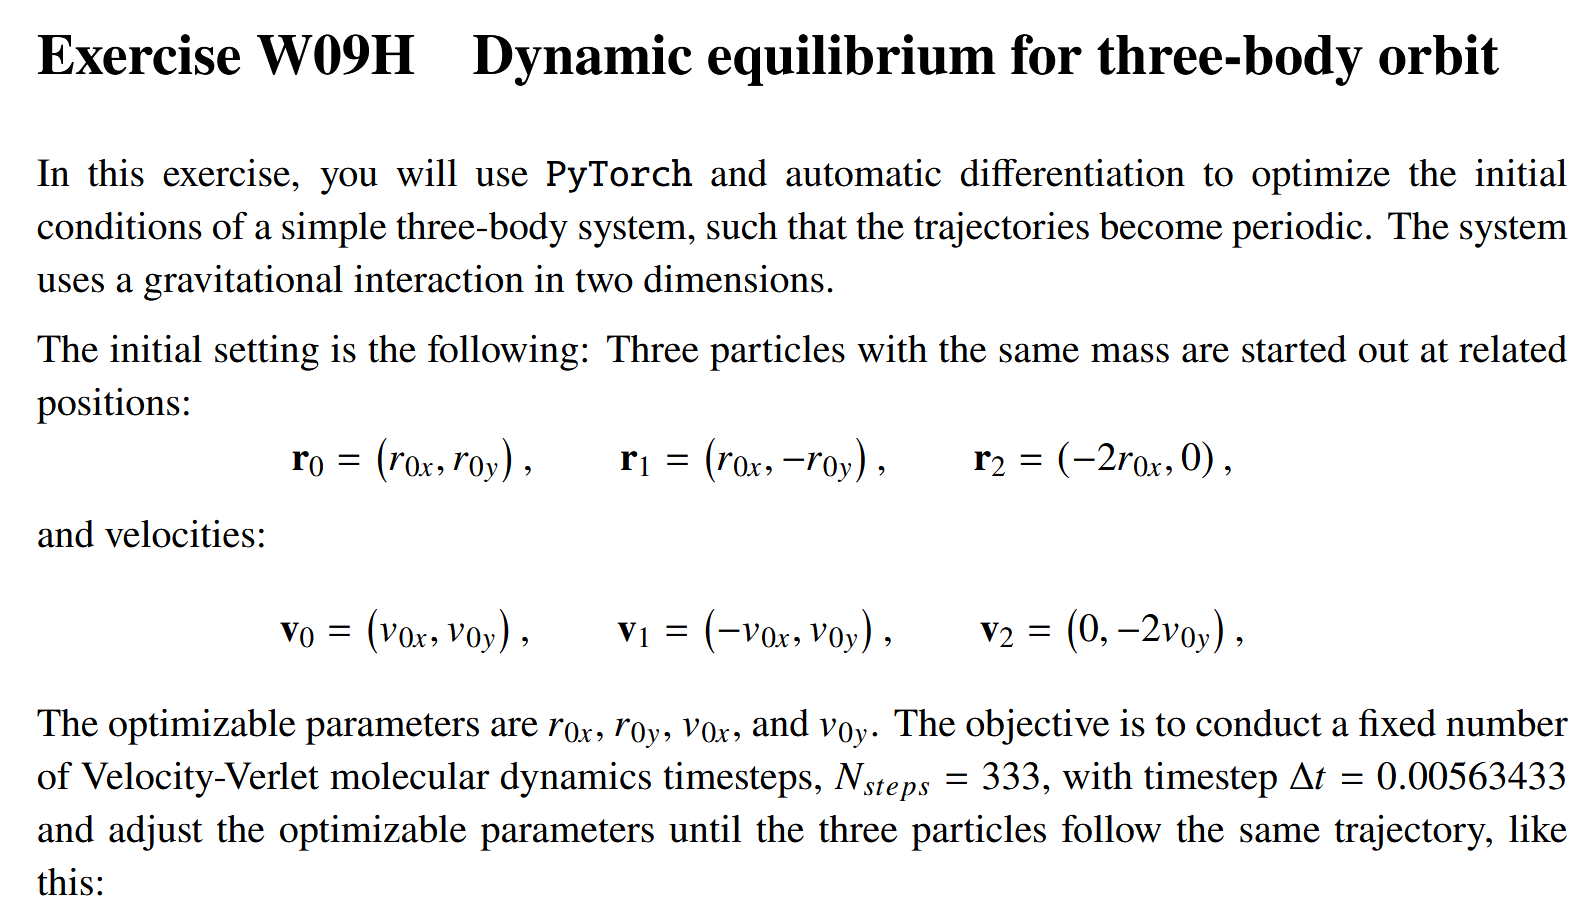
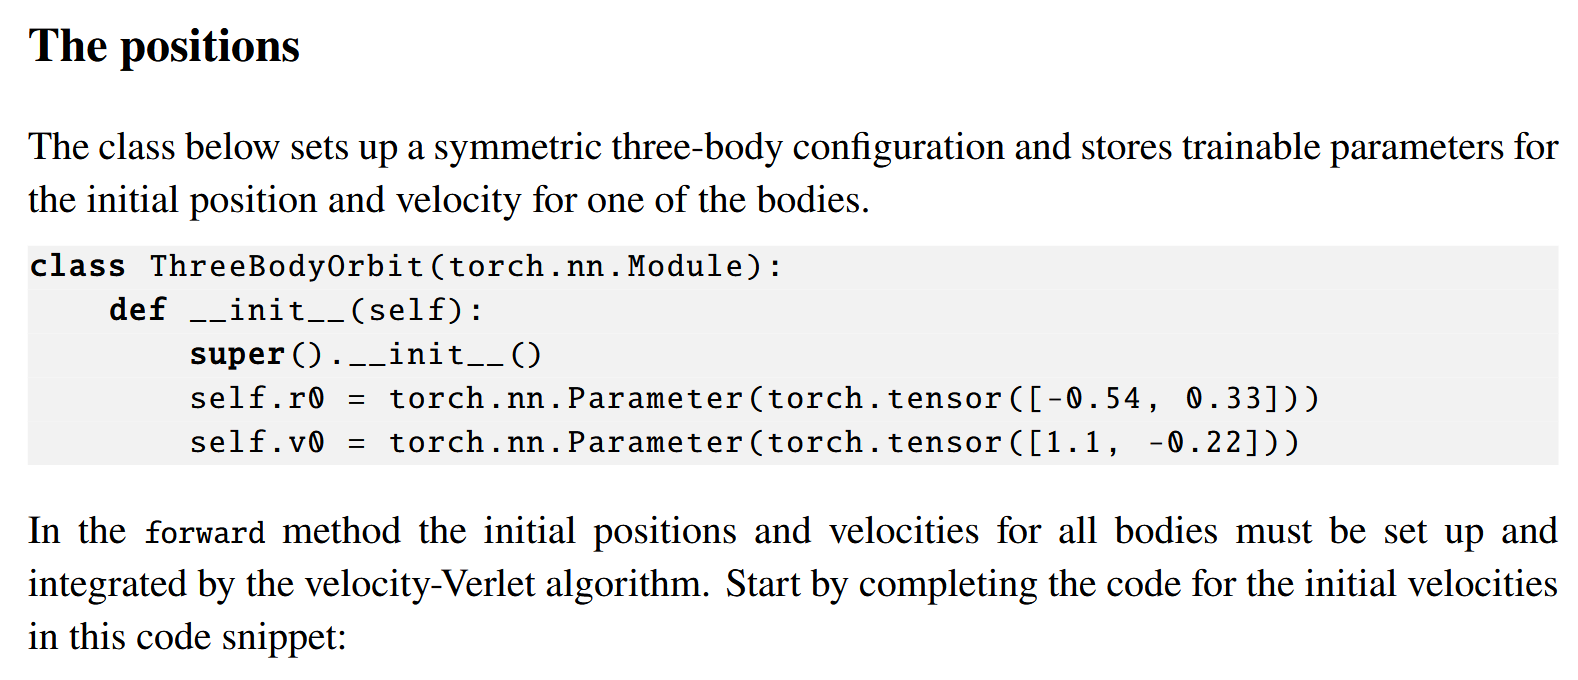

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np


class ThreeBodyOrbit(nn.Module):
    def __init__(self, *args, r0=[-0.54, 0.33], v0=[1.1, -0.22], **kwargs):
        super().__init__(*args, **kwargs)
        self.r0 = torch.tensor(r0)
        self.v0 = torch.tensor(v0)

    def forward(self):
        pos0 = torch.stack([self.r0, 
                            torch.stack([self.r0[0], -self.r0[1]]), 
                            torch.stack([-2*self.r0[0], torch.tensor(0.0)])
                            ])
        
        vel0 = torch.stack([self.v0, 
                            torch.stack([-self.v0[0], self.v0[1]]), 
                            torch.stack([torch.tensor(0.0), -2*self.v0[1]])
                            ])
            
        pos, vel = pos0, vel0
        dt = self.dt

        return pos, vel, pos0, vel0

def grav_force(pos, G=1.0, eps=1e-7):
    N = pos.shape[0]
    force = torch.zeros_like(pos)
    